# Cleaning effects and PCA

Notebook 01 explored the **raw** data on a temporary copy where every `<x` was a NaN. This notebook (1) re-checks
what the cleaning rules of `src/cleaning.py` change in the conclusions of 4.A, 4.B and 4.C, including how much they
depend on the censoring rule, and (2) runs several PCAs to understand the structure of the data and how much of it
is a structure of *studies*.

PCA is exploratory and unsupervised (no target involved), so it is fitted on all rows; using a PCA as a model input
would require fitting it inside each training fold (notebook 03).

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis import (eta_squared, pca_report, source_demeaned_correlations,
                          standardise_for_pca)
from src.cleaning import clean_dataframe
from src.config import (CENSORED_COLUMNS, FIGURES_DIR, NUMERIC_COLUMNS, NUMERIC_FEATURES,
                        RESULTS_DIR, TARGETS)
from src.loading import load_raw
from src.preprocessing import build_preprocessor, feature_spec

FIG = FIGURES_DIR / "preprocessing_pca"
FIG.mkdir(parents=True, exist_ok=True)
OUT = RESULTS_DIR / "preprocessing_pca"
OUT.mkdir(parents=True, exist_ok=True)

raw = load_raw()
clean = clean_dataframe(raw)
source = clean["source"]

# What notebook 01 worked on: censored values and composite codes coerced to NaN.
old = raw[NUMERIC_COLUMNS].apply(pd.to_numeric, errors="coerce")
new = clean[NUMERIC_COLUMNS]
print(clean.shape, "| study groups:", source.nunique())

(1652, 60) | study groups: 33


## 1. What cleaning changes in the conclusions of 01

### 1.1 Sample sizes and reliability tiers (4.B)

                  n_raw_copy  n_clean  gain  censored_values
b_conc_ppm                85      504   419              419
al_conc_ppm              502      905   403              403
v_conc_wt                620      928   308              308
nb_conc_ppm              453      752   299              299
ti_conc_ppm              865      935    70               70
n_conc_ppm              1183     1242    59                0
interpass_temp_c        1614     1652    38                0
cu_conc_wt               564      578    14               14
as_conc_ppm              226      234     8                8
s_conc_wt               1641     1648     7                7


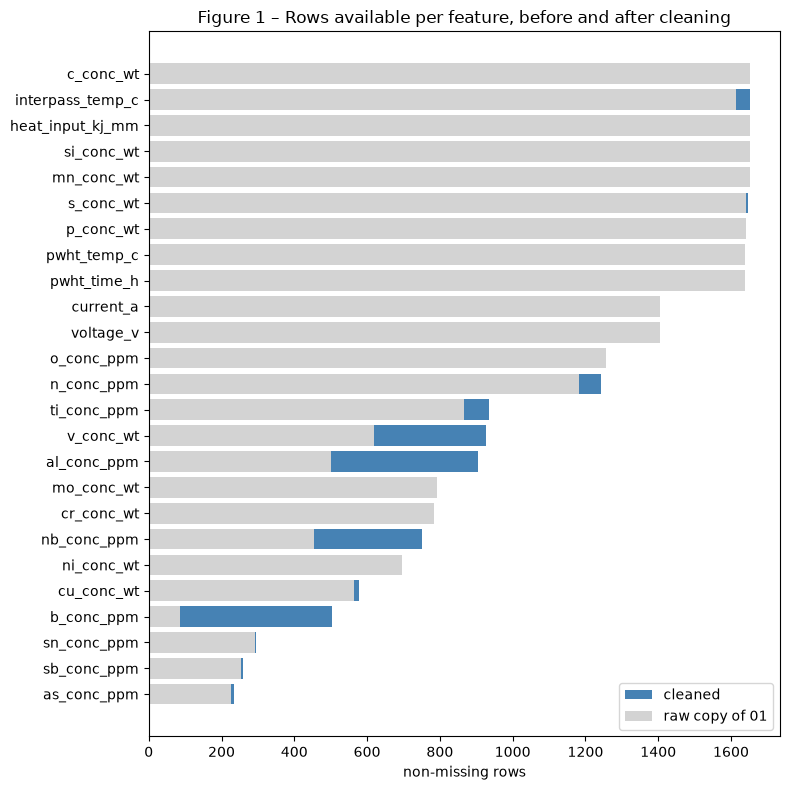


Share of column pairs per reliability tier (%), and columns kept by the n >= 100 filter:
                       raw copy  cleaned
medium (300-999)           50.5     52.5
fragile (<300)             33.1     32.8
solid (>=1000)             16.3     14.8
columns with n >= 100      31.0     33.0


In [2]:
n_old, n_new = old[NUMERIC_FEATURES].notna().sum(), new[NUMERIC_FEATURES].notna().sum()
censored = {c: int(clean[f"{c}_censored"].sum()) for c in CENSORED_COLUMNS}
counts = pd.DataFrame({"n_raw_copy": n_old, "n_clean": n_new, "gain": n_new - n_old,
                       "censored_values": pd.Series(censored).reindex(NUMERIC_FEATURES)}).fillna(0).astype(int)
counts.to_csv(OUT / "02_counts_before_after.csv")
print(counts.sort_values("gain", ascending=False).head(10).to_string())

order = counts.sort_values("n_clean").index
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(order, counts.loc[order, "n_clean"], color="steelblue", label="cleaned")
ax.barh(order, counts.loc[order, "n_raw_copy"], color="lightgray", label="raw copy of 01")
ax.set_xlabel("non-missing rows")
ax.set_title("Figure 1 \u2013 Rows available per feature, before and after cleaning")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "fig01_counts_before_after.png", dpi=150)
plt.show()


def pair_tiers(frame, min_count=100):
    kept = frame.loc[:, frame.notna().sum() >= min_count]
    avail = kept.notna().astype(int)
    pairs = (avail.T @ avail).to_numpy()[np.triu_indices(kept.shape[1], k=1)]
    tiers = pd.cut(pairs, [0, 300, 1000, 10_000], labels=["fragile (<300)", "medium (300-999)", "solid (>=1000)"], right=False)
    return kept.shape[1], pd.Series(tiers).value_counts(normalize=True).mul(100).round(1)


summary = pd.DataFrame({"raw copy": pair_tiers(old)[1], "cleaned": pair_tiers(new)[1]})
summary.loc["columns with n >= 100"] = [pair_tiers(old)[0], pair_tiers(new)[0]]
summary.to_csv(OUT / "02_reliability_tiers.csv")
print("\nShare of column pairs per reliability tier (%), and columns kept by the n >= 100 filter:")
print(summary.to_string())

**Your conclusions:**

- **Cleaning restores a lot of rows**: boron 85 -> 504 (+419), aluminium 502 -> 905 (+403), vanadium 620 -> 928 (+308), niobium 453 -> 752 (+299), titanium +70, nitrogen +59 (composite codes), interpass temperature +38 (the `150-200` range). Targets are untouched.
- **The reliability tiers of 4.B hold**: the share of column pairs is fragile (n < 300) 33.1% -> 32.8%, medium 50.5% -> 52.5%, solid (n >= 1000) 16.3% -> 14.8%. The fragile pairs are mostly those involving a target or Sn / As / Sb (234-296 rows each), which cleaning does not touch. B, Al and Nb leave the fragile tier individually. Two columns pass the `n >= 100` filter that did not before: boron, and hardness (138 values now parsed).

### 1.2 Distributions and outliers (4.A)

Largest changes of skewness (|z| > 4 outliers in the last columns):
                  skew_raw  skew_clean  outliers_raw  outliers_clean  censored_share_%
b_conc_ppm            1.31        4.28             0               8              83.0
nb_conc_ppm           1.41        2.12             0               0              40.0
v_conc_wt             1.09        1.69             0               0              33.0
al_conc_ppm           1.47        2.04             0               4              45.0
ti_conc_ppm           2.55        2.69             4               4               7.0
n_conc_ppm            2.71        2.78            12              14               NaN
sn_conc_ppm           8.60        8.66             2               2               2.0
cu_conc_wt            2.73        2.77             9               9               2.0
as_conc_ppm           2.10        2.06             2               2               3.0
interpass_temp_c      0.16        0.20             4          

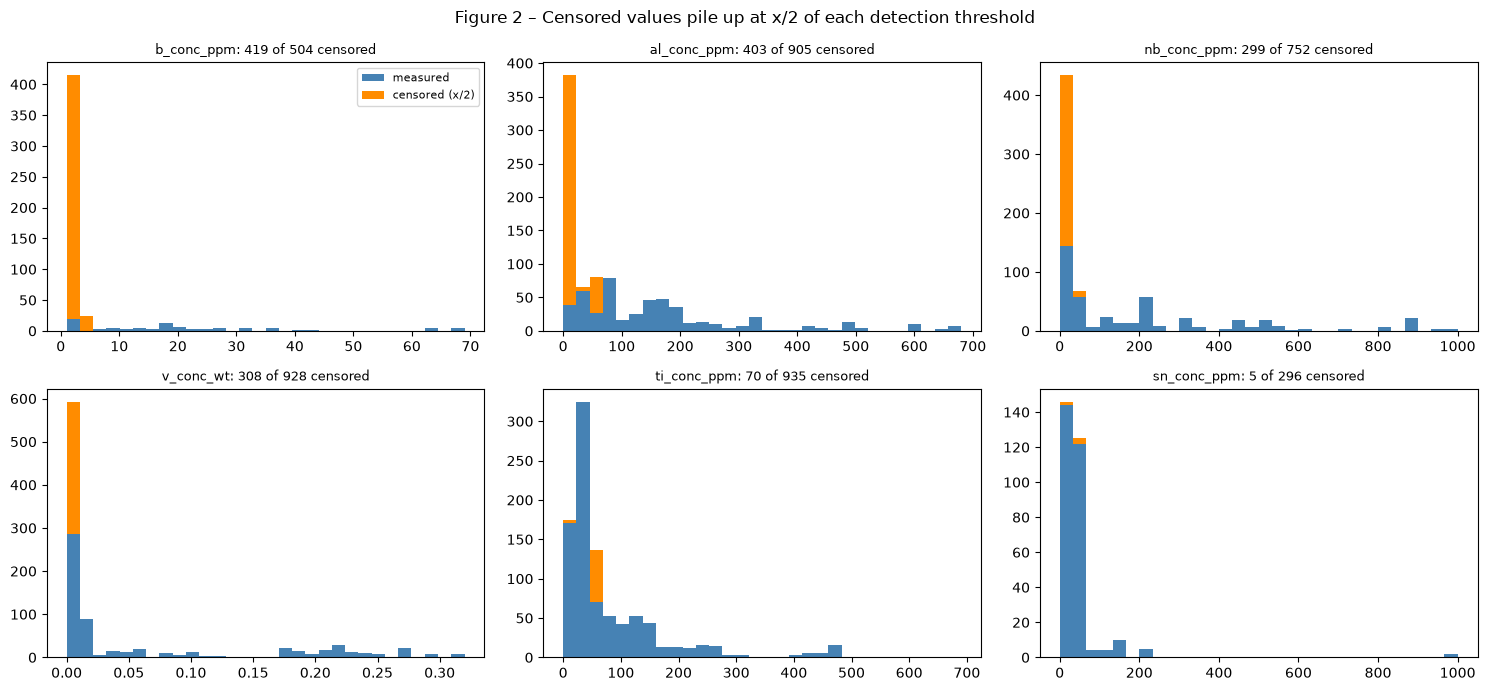

In [3]:
def skew(frame):
    return frame[NUMERIC_FEATURES].skew()


def n_outliers(frame, z=4):
    zs = (frame[NUMERIC_FEATURES] - frame[NUMERIC_FEATURES].mean()) / frame[NUMERIC_FEATURES].std()
    return (zs.abs() > z).sum()


shape = pd.DataFrame({"skew_raw": skew(old), "skew_clean": skew(new),
                      "outliers_raw": n_outliers(old), "outliers_clean": n_outliers(new)}).round(2)
shape["censored_share_%"] = (100 * pd.Series(censored) / n_new).reindex(shape.index).round(0)
shape.to_csv(OUT / "02_skew_outliers_before_after.csv")
changed = shape.loc[(shape.skew_raw - shape.skew_clean).abs().sort_values(ascending=False).index].head(10)
print("Largest changes of skewness (|z| > 4 outliers in the last columns):")
print(changed.to_string())

columns = ["b_conc_ppm", "al_conc_ppm", "nb_conc_ppm", "v_conc_wt", "ti_conc_ppm", "sn_conc_ppm"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, column in zip(axes.flat, columns):
    flag = clean[f"{column}_censored"]
    ax.hist([clean.loc[~flag, column].dropna(), clean.loc[flag, column]], bins=30, stacked=True,
            color=["steelblue", "darkorange"], label=["measured", "censored (x/2)"])
    ax.set_title(f"{column}: {flag.sum()} of {clean[column].notna().sum()} censored", fontsize=9)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Figure 2 \u2013 Censored values pile up at x/2 of each detection threshold")
plt.tight_layout()
fig.savefig(FIG / "fig02_censored_spikes.png", dpi=150)
plt.show()

**Your conclusions:**

- **The skew of the censored impurities was underestimated in 01, as flagged there**: B 1.31 -> 4.28, Al 1.47 -> 2.04, Nb 1.41 -> 2.12, V 1.09 -> 1.69; and |z| > 4 outliers appear (B 0 -> 8, Al 0 -> 4). Columns with little censoring (Sn 8.6, Cu 2.7, Ti 2.7) do not change.
- **The extra skew is a pile-up, not a tail**: 83% of boron and 33-45% of Al, Nb and V sit on a few values (x/2 of each detection threshold; Al has a second pile near 50). The `_censored` flag is what lets a model tell these from measurements; a log transform alone would not remove the spike.
- **Consequence**: Al, Nb and V now have |skew| > 1.6 and are candidates for the shifted log of the linear family (currently S, P, Cu, Sn, B, As).

### 1.3 Pearson against Spearman (4.B)

columns kept by n >= 100: raw 31 -> clean 33 | new: ['b_conc_ppm', 'hardness_kgf_mm2']
common columns, share of pairs with |Spearman - Pearson| > 0.3 and mean |diff|:
  raw copy: (12.7, 0.137) | cleaned: (12.9, 0.142)

Largest divergences on cleaned data (Spearman - Pearson):
co_conc_wt  voltage_v     -0.73
v_conc_wt   co_conc_wt     0.66
ni_conc_wt  co_conc_wt     0.64
mo_conc_wt  co_conc_wt     0.64
v_conc_wt   cu_conc_wt     0.63
cu_conc_wt  nb_conc_ppm    0.63
s_conc_wt   co_conc_wt    -0.63
co_conc_wt  nb_conc_ppm    0.60
p_conc_wt   co_conc_wt    -0.57
ni_conc_wt  v_conc_wt      0.56


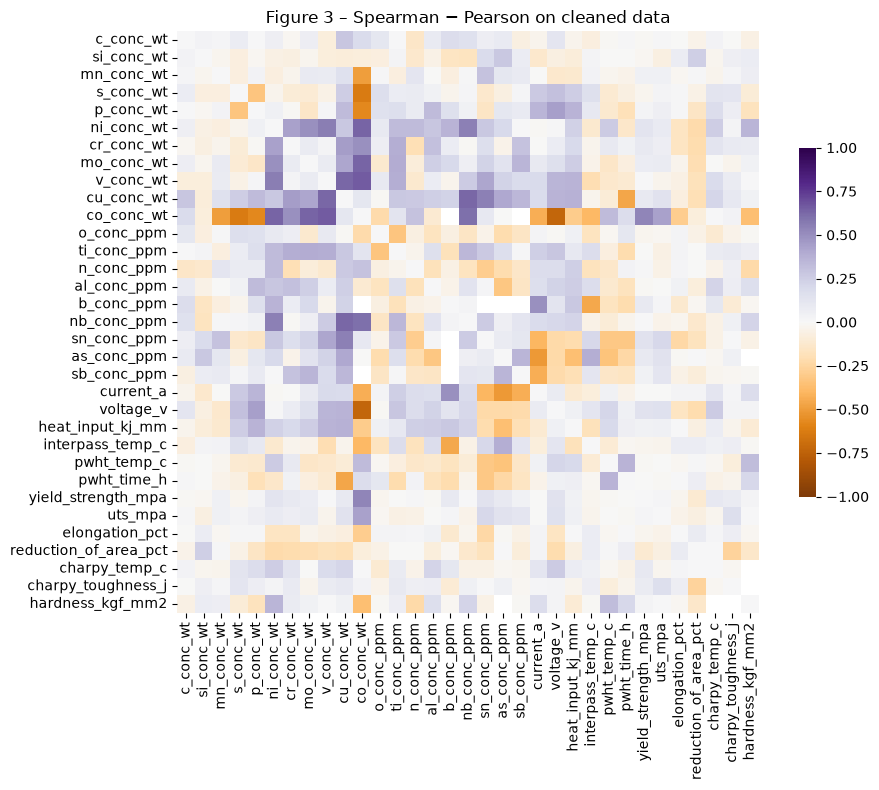

In [4]:
def divergence(frame, min_count=100):
    kept = frame.loc[:, frame.notna().sum() >= min_count]
    return kept, (kept.corr(method="spearman") - kept.corr(method="pearson"))


kept_old, diff_old = divergence(old)
kept_new, diff_new = divergence(new)
common = [c for c in kept_old.columns if c in kept_new.columns]


def share_above(diff, columns, threshold=0.3):
    sub = diff.loc[columns, columns].to_numpy()[np.triu_indices(len(columns), k=1)]
    sub = sub[~np.isnan(sub)]          # pairs without any overlapping row have no coefficient
    return round(float((np.abs(sub) > threshold).mean() * 100), 1), round(float(np.abs(sub).mean()), 3)


print("columns kept by n >= 100: raw", kept_old.shape[1], "-> clean", kept_new.shape[1],
      "| new:", [c for c in kept_new.columns if c not in kept_old.columns])
print("common columns, share of pairs with |Spearman - Pearson| > 0.3 and mean |diff|:")
print("  raw copy:", share_above(diff_old, common), "| cleaned:", share_above(diff_new, common))

pairs = diff_new.where(np.triu(np.ones(diff_new.shape, bool), k=1)).stack()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10)
print("\nLargest divergences on cleaned data (Spearman - Pearson):")
print(top.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(diff_new, cmap="PuOr", vmin=-1, vmax=1, center=0, square=True, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Figure 3 \u2013 Spearman \u2212 Pearson on cleaned data")
plt.tight_layout()
fig.savefig(FIG / "fig03_spearman_minus_pearson_clean.png", dpi=150)
plt.show()

**Your conclusions:**

- **Pearson / Spearman divergence is unchanged in size**: on the 31 common columns, the share of pairs with |Spearman - Pearson| > 0.3 goes from 12.7% to 12.9% and the mean |difference| from 0.137 to 0.142.
- **Where it sits changes slightly**: 7 of the 10 largest divergences involve `co_conc_wt` (n < 130, already excluded from modeling) and the others are inside the alloy block (V-Cu, Cu-Nb, Ni-V). `current_a` and `voltage_v`, singled out in 01, no longer appear in the top 10: their divergence there came mostly through their pairs with Co.

### 1.4 Correlations by block (4.C)

In [5]:
ow = source_demeaned_correlations(old, source, NUMERIC_FEATURES, TARGETS)
nw = source_demeaned_correlations(new, source, NUMERIC_FEATURES, TARGETS)
both = ow.merge(nw, on=["input", "target"], how="outer", suffixes=("_raw", "_clean"))
both.to_csv(OUT / "02_input_target_raw_vs_clean.csv", index=False)

ranking = both.reindex(both["rho_overall_raw"].abs().sort_values(ascending=False).index).head(15)
print("Top 15 input-target pairs of notebook 01 (overall rho, n) and their cleaned values:")
print(ranking[["input", "target", "n_raw", "rho_overall_raw", "n_clean", "rho_overall_clean",
               "rho_within_raw", "rho_within_clean"]].round(2).to_string(index=False))

new_top = both.reindex(both["rho_overall_clean"].abs().sort_values(ascending=False).index).head(15)
print("\nTop 10 of the cleaned ranking, by overall rho:")
print(new_top[["input", "target", "n_clean", "rho_overall_clean", "rho_within_clean"]].head(10).round(2).to_string(index=False))

alloy = ["cr_conc_wt", "mo_conc_wt", "v_conc_wt", "nb_conc_ppm"]
red = pd.DataFrame({"raw copy": old[alloy].corr(method="spearman").stack(),
                    "cleaned": new[alloy].corr(method="spearman").stack()})
red = red[[a < b for a, b in red.index]]
print("\nRedundancy of the Cr / Mo / V / Nb block (Spearman):")
print(red.round(2).to_string())
t_old = old[TARGETS].corr(method="spearman"); t_new = new[TARGETS].corr(method="spearman")
print("\nTargets vs targets, largest change between raw copy and cleaned:",
      round(float((t_new - t_old).abs().to_numpy().max()), 3))

Top 15 input-target pairs of notebook 01 (overall rho, n) and their cleaned values:
           input                target  n_raw  rho_overall_raw  n_clean  rho_overall_clean  rho_within_raw  rho_within_clean
       voltage_v reduction_of_area_pct  592.0            -0.67      592              -0.67           -0.20             -0.20
      cr_conc_wt        elongation_pct  357.0            -0.60      357              -0.60           -0.43             -0.43
heat_input_kj_mm reduction_of_area_pct  705.0            -0.58      705              -0.58           -0.10             -0.10
     nb_conc_ppm        elongation_pct  258.0            -0.58      377              -0.51           -0.46             -0.52
       v_conc_wt    yield_strength_mpa  321.0             0.57      449               0.52            0.32              0.40
       current_a reduction_of_area_pct  592.0            -0.56      592              -0.56           -0.17             -0.17
      cr_conc_wt               uts_mpa  3

**Your conclusions:**

- **Pairs without a censored column are identical** to 01, so the central result of 4.E stands: voltage, heat input, current, S and P vs reduction of area keep -0.53 to -0.67 overall and only -0.10 to -0.20 within a study. Targets vs targets: largest change 0.0.
- **Censored columns move modestly, in the favourable direction for Cr / V / Nb**: Nb vs elongation within a study -0.46 -> -0.52 (n 258 -> 377), V vs yield 0.32 -> 0.40, V vs UTS 0.42 -> 0.45, V vs elongation -0.36 -> -0.43. These drivers get stronger with more rows.
- **One 01 finding does not survive**: B vs UTS was 0.50 within a study on 45 rows from 4 studies; with 259 rows it is 0.14. It was a small-sample artefact. The new B vs reduction of area (-0.66 overall, n = 242) is again between-study (-0.24 within).
- **Alloy redundancy holds, with a correction**: Cr-Mo 0.72, Cr-V 0.82, Cr-Nb 0.80 (was 0.88), Mo-V 0.71, Mo-Nb 0.75 (0.82), and Nb-V 0.83 (it was 0.56 only because Nb and V overlapped on fewer rows). The block is redundant at 0.71-0.83.

### 1.5 Sensitivity to the censoring rule

Skewness of the heavily censored impurities, by censoring rule:
             x/2 (chosen)     x     0   NaN
b_conc_ppm           4.28  4.44  4.05  1.31
al_conc_ppm          2.04  2.03  2.01  1.47
nb_conc_ppm          2.12  2.12  2.11  1.41
v_conc_wt            1.69  1.69  1.69  1.09
ti_conc_ppm          2.69  2.60  2.61  2.55
sn_conc_ppm          8.66  8.60  8.65  8.60

Within-source correlations compared with the chosen rule:
        rule  pairs  rank_corr_with_x/2  max_abs_change  sign_flips (|rho|>0.1 both)  membership_changes (|rho_within|>=0.3)
x/2 (chosen)    125               1.000           0.000                            0                                       0
           x    125               0.993           0.090                            0                                       2
           0    125               0.997           0.064                            0                                       0
         NaN    121               0.959           0.363              

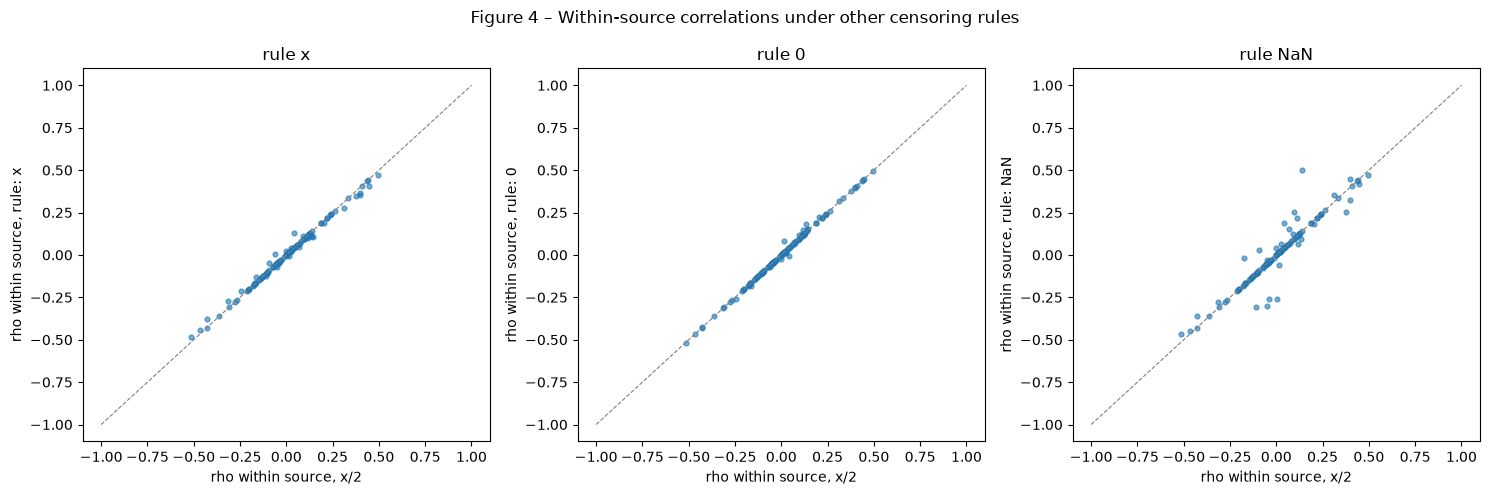

In [6]:
variants = {"x/2 (chosen)": 0.5, "x": 1.0, "0": 0.0, "NaN": None}
skew_rows, within = {}, {}
for name, factor in variants.items():
    frame = clean_dataframe(raw, censored_factor=factor)
    skew_rows[name] = frame[columns].skew()
    within[name] = source_demeaned_correlations(frame[NUMERIC_COLUMNS], frame["source"], NUMERIC_FEATURES, TARGETS)
print("Skewness of the heavily censored impurities, by censoring rule:")
print(pd.DataFrame(skew_rows).round(2).to_string())

base = within["x/2 (chosen)"].set_index(["input", "target"])
rows, fig_data = [], {}
for name, table in within.items():
    t = table.set_index(["input", "target"])
    common_pairs = base.index.intersection(t.index)
    a, b = base.loc[common_pairs, "rho_within"], t.loc[common_pairs, "rho_within"]
    rows.append({"rule": name, "pairs": len(common_pairs), "rank_corr_with_x/2": round(a.corr(b, method="spearman"), 3),
                 "max_abs_change": round((a - b).abs().max(), 3),
                 "sign_flips (|rho|>0.1 both)": int(((np.sign(a) != np.sign(b)) & (a.abs() > 0.1) & (b.abs() > 0.1)).sum()),
                 "membership_changes (|rho_within|>=0.3)": int(((a.abs() >= 0.3) != (b.abs() >= 0.3)).sum())})
    fig_data[name] = (a, b)
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(OUT / "02_censoring_sensitivity.csv", index=False)
print("\nWithin-source correlations compared with the chosen rule:")
print(sensitivity.to_string(index=False))

a, b = fig_data["NaN"]
moved = (a - b).abs().sort_values(ascending=False).head(6).index
print("\nPairs that move most when censored values are left as NaN (rho within source):")
print(pd.DataFrame({"x/2": a[moved], "NaN": b[moved]}).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, ["x", "0", "NaN"]):
    a, b = fig_data[name]
    ax.scatter(a, b, s=12, alpha=0.6)
    ax.plot([-1, 1], [-1, 1], color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlabel("rho within source, x/2")
    ax.set_ylabel(f"rho within source, rule: {name}")
    ax.set_title(f"rule {name}")
fig.suptitle("Figure 4 \u2013 Within-source correlations under other censoring rules")
plt.tight_layout()
fig.savefig(FIG / "fig04_censoring_sensitivity.png", dpi=150)
plt.show()

**Your conclusions:**

- **The value given to a censored result barely matters**: `x/2`, `x` and `0` give within-source correlations with a rank correlation of 0.993-0.997 against the chosen rule, no sign flip, a largest change of 0.09, and 0-2 pairs crossing the |rho| = 0.3 line. The skewness of B, Al, Nb and V differs by at most 0.4 between the three. The `x/2` assumption is not driving the conclusions.
- **What matters is keeping the censored rows**: leaving them as NaN (what 01 did) lowers the rank correlation to 0.959, changes some pairs by up to 0.36 (B vs UTS 0.14 -> 0.50, Al vs reduction of area 0.01 -> -0.26, Nb vs Charpy -0.05 -> -0.30) and moves 5 pairs across the 0.3 line.
- **The NaN version is the biased one**: dropping `<x` rows keeps only the above-detection tail of each impurity, and which studies have a high detection limit is itself a study property. `x/2` plus the flag is the safer default.

### 1.6 Verdict on the conclusions of 01

The conclusions of 01 that cleaning could change, after this notebook:

| Section of 01 | Conclusion | Verdict | Evidence |
|---|---|---|---|
| 4.A | Impurities right-skewed, skew underestimated | **Confirmed, larger** | B 1.31 -> 4.28, Al 1.47 -> 2.04, Nb 1.41 -> 2.12, V 1.09 -> 1.69 |
| 4.A | Outliers are genuine long tails | **Confirmed** | new |z| > 4 rows come from the censoring pile-up and long tails; none looks like an entry error |
| 4.A | Multimodality (Mn, Cr, Mo, V), PWHT / interpass spikes, Charpy 100 J spike | Unchanged | columns not touched by cleaning |
| 4.B | Three reliability tiers | **Confirmed** | 33 / 51 / 16% -> 33 / 53 / 15% of pairs |
| 4.B | Divergence between Pearson and Spearman concentrated on a few columns | **Partly changed** | same size (12.9%), but 7 of the top 10 involve Co; current / voltage no longer stand out |
| 4.C | Alloy block Cr / Mo / V / Nb is redundant | **Confirmed** | 0.71-0.83 (Nb-V corrected from 0.56 to 0.83) |
| 4.C | Strength / ductility / toughness trade-off | **Confirmed** | targets vs targets unchanged (change 0.0) |
| 4.C / 4.E | Process variables look strong overall but are mostly between-study | **Confirmed** | voltage / heat input / current vs reduction of area: -0.6 overall, -0.1 to -0.2 within |
| 4.C / 4.E | Cr, V, Nb are credible drivers | **Confirmed, stronger** | Nb vs elongation within -0.46 -> -0.52, V vs yield 0.32 -> 0.40 |
| 4.E | B vs UTS 0.50 within a study | **Refuted** | 0.14 with 259 rows instead of 45 |


## 2. PCA

Four PCAs, from the cleanest to the most diagnostic. All variables are z-scored; the skewed impurities
(S, P, Cu, Sn, B, As) get the shifted log of `src.preprocessing.LogShift` first.

| # | Input | Rows | Missing values |
|---|---|---|---|
| 1 | **Core**: the 13 numeric features missing in at most 25% of rows | rows complete on the core | none to fill |
| 2 | **Alloy block**: Ni, Cr, Mo, V, Cu | rows where the five are reported | none to fill |
| 3 | All 25 numeric features | all rows | median |
| 4 | Output of the `linear` preprocessor (numeric + missing/censored flags + one-hot), standardised | all rows | median |

Study visibility is measured by the adjusted eta-squared of each component against `source` (groups of at least 5 rows)
and against `weld_type`: the share of the variance of the component explained by the group. The number of components
carrying signal comes from a parallel analysis (eigenvalues above those of column-shuffled data, 95th percentile).

In [7]:
rate = clean[NUMERIC_FEATURES].isna().mean()
core = [c for c in NUMERIC_FEATURES if rate[c] <= 0.25]
alloy_block = ["ni_conc_wt", "cr_conc_wt", "mo_conc_wt", "v_conc_wt", "cu_conc_wt"]
weld = clean["weld_type"]
top_sources = source.value_counts().index[:8]
palette = dict(zip(top_sources, plt.cm.tab10.colors))
reports, summary_rows = {}, []


def summarise(name, report):
    index = report.scores.index
    row = {"pca": name, "rows": len(index), "variables": report.correlations.shape[0],
           "var_PC1_%": round(100 * report.explained_ratio.iloc[0], 1),
           "var_PC2_%": round(100 * report.explained_ratio.iloc[1], 1),
           "var_PC3_%": round(100 * report.explained_ratio.iloc[2], 1),
           "cum_PC1-3_%": round(100 * report.explained_ratio.iloc[:3].sum(), 1),
           "comps_80%": report.components_for(0.8), "comps_90%": report.components_for(0.9),
           "comps_95%": report.components_for(0.95), "parallel_keep": report.n_keep,
           "cum_at_parallel_keep_%": round(100 * report.explained_ratio.iloc[:report.n_keep].sum(), 1)}
    for k in (1, 2, 3):
        row[f"eta2_source_PC{k}"] = round(eta_squared(report.scores[f"PC{k}"], source.loc[index]), 2)
        row[f"eta2_weld_PC{k}"] = round(eta_squared(report.scores[f"PC{k}"], weld.loc[index]), 2)
    summary_rows.append(row)


def pca_figure(name, report, filename, label_threshold=0.0):
    index = report.scores.index
    ev = report.explained_ratio * 100
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    ax = axes[0, 0]
    k = min(15, len(ev))
    ax.bar(range(1, k + 1), ev.iloc[:k], color="steelblue")
    ax.plot(range(1, k + 1), report.parallel["threshold"].iloc[:k] / len(ev) * 100, "o--", color="darkorange",
            label="parallel analysis (95th pct)")
    ax2 = ax.twinx()
    ax2.plot(range(1, k + 1), ev.cumsum().iloc[:k], color="black", marker=".")
    ax2.set_ylim(0, 100)
    ax2.set_ylabel("cumulative %")
    ax.set_xlabel("component")
    ax.set_ylabel("% of variance")
    ax.set_title("Scree plot")
    ax.legend(fontsize=8)
    ax = axes[0, 1]
    corr = report.correlations
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray"))
    for variable, row in corr.iterrows():
        if np.hypot(row["PC1"], row["PC2"]) >= label_threshold:
            ax.annotate("", (row["PC1"], row["PC2"]), (0, 0), arrowprops=dict(arrowstyle="->", color="steelblue"))
            ax.text(row["PC1"] * 1.05, row["PC2"] * 1.05, variable, fontsize=7)
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")
    ax.set_xlabel(f"PC1 ({ev.iloc[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({ev.iloc[1]:.0f}%)")
    ax.set_title("Circle of correlations")
    for ax, labels, title in [(axes[1, 0], source.loc[index], "coloured by study"),
                              (axes[1, 1], weld.loc[index], "coloured by weld type")]:
        scores = report.scores
        if title.endswith("study"):
            colours = labels.map(palette).fillna("lightgray")
            ax.scatter(scores["PC1"], scores["PC2"], s=10, alpha=0.6, c=colours)
            handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=c, label=s) for s, c in palette.items()]
            ax.legend(handles=handles, fontsize=7, title="top 8 studies", title_fontsize=7)
        else:
            for level, colour in zip(sorted(labels.unique()), plt.cm.Set2.colors):
                m = labels == level
                ax.scatter(scores.loc[m, "PC1"], scores.loc[m, "PC2"], s=10, alpha=0.6, color=colour, label=level)
            ax.legend(fontsize=7)
        ax.set_xlabel(f"PC1 ({ev.iloc[0]:.0f}%)")
        ax.set_ylabel(f"PC2 ({ev.iloc[1]:.0f}%)")
        ax.set_title(f"Scores {title}")
    fig.suptitle(name)
    plt.tight_layout()
    fig.savefig(FIG / filename, dpi=150)
    plt.show()


def loadings_table(report, k=3, top=6):
    return {f"PC{i}": report.correlations[f"PC{i}"].reindex(
        report.correlations[f"PC{i}"].abs().sort_values(ascending=False).index).head(top).round(2).to_dict()
        for i in range(1, k + 1)}

### 2.1 PCA 1: core variables, complete rows

13 variables: ['c_conc_wt', 'si_conc_wt', 'mn_conc_wt', 's_conc_wt', 'p_conc_wt', 'o_conc_ppm', 'n_conc_ppm', 'current_a', 'voltage_v', 'heat_input_kj_mm', 'interpass_temp_c', 'pwht_temp_c', 'pwht_time_h']
loadings (correlation variable-component):
  PC1 {'current_a': 0.89, 'heat_input_kj_mm': 0.89, 'voltage_v': 0.81, 's_conc_wt': 0.66, 'p_conc_wt': 0.63, 'pwht_time_h': -0.34}
  PC2 {'pwht_temp_c': 0.72, 'o_conc_ppm': 0.63, 'n_conc_ppm': 0.62, 'interpass_temp_c': -0.6, 'pwht_time_h': 0.52, 'si_conc_wt': -0.45}
  PC3 {'c_conc_wt': 0.7, 'si_conc_wt': -0.51, 's_conc_wt': -0.44, 'p_conc_wt': -0.39, 'o_conc_ppm': -0.37, 'mn_conc_wt': -0.34}


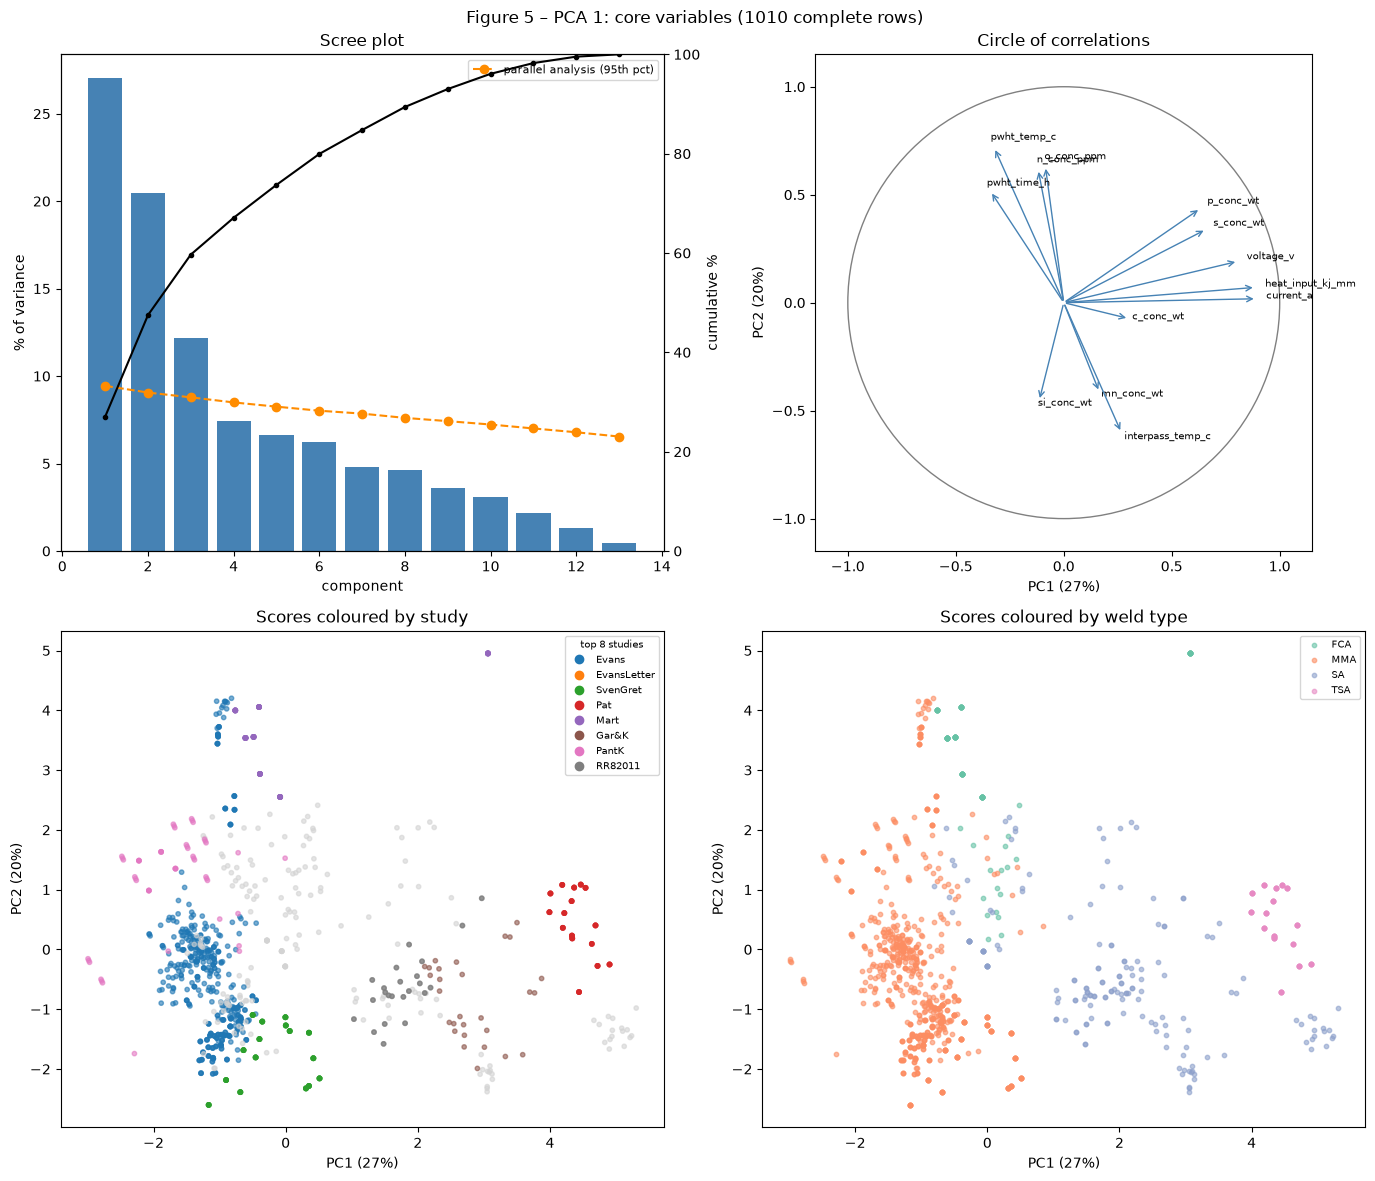

In [8]:
core_rows = clean.loc[clean[core].notna().all(axis=1), core]
reports["1 core"] = pca_report(standardise_for_pca(core_rows))
summarise("1 core", reports["1 core"])
print(len(core), "variables:", core)
print("loadings (correlation variable-component):")
for pc, values in loadings_table(reports["1 core"]).items():
    print(" ", pc, values)
pca_figure("Figure 5 \u2013 PCA 1: core variables (1010 complete rows)", reports["1 core"], "fig05_pca1_core.png")

**Your conclusions:**

- **Three axes, each a different part of the process**: PC1 (27%) is the arc-energy axis (current 0.89, heat input 0.89, voltage 0.81, with S 0.66 and P 0.63); PC2 (20%) is post-weld heat treatment with O and N (PWHT temperature 0.72, O 0.63, N 0.62, interpass temperature -0.60); PC3 (12%) opposes C (0.70) to Si (-0.51).
- **Weakly compressible**: parallel analysis keeps 3 components (60% of the variance) and 80 / 90 / 95% need 7 / 9 / 10 of the 13 variables.
- **The axes are study axes**: the adjusted eta-squared against `source` is 0.93 for PC1, 0.60 for PC2 and 0.63 for PC3 (and 0.80 against `weld_type` for PC1). In Figure 5 each study occupies its own zone along PC1 (Pat on the right, PantK and Evans on the left).
- **The most distant rows are replicates, not errors**: the ten farthest rows are all `Mart-G*` with exactly the same T2 (identical input vectors), see 2.7.

### 2.2 PCA 2: alloy block (Ni, Cr, Mo, V, Cu)

rows by study: {'EvansLetter': 156, 'PantK': 54, 'Gar&K': 50, 'RR82011': 46, 'Cunh': 38, 'Ditt': 20}
  PC1 {'cr_conc_wt': 0.96, 'v_conc_wt': 0.93, 'mo_conc_wt': 0.86, 'cu_conc_wt': 0.09, 'ni_conc_wt': -0.09}
  PC2 {'ni_conc_wt': 0.76, 'cu_conc_wt': -0.75, 'cr_conc_wt': 0.09, 'v_conc_wt': 0.05, 'mo_conc_wt': 0.01}
  PC3 {'cu_conc_wt': 0.65, 'ni_conc_wt': 0.64, 'mo_conc_wt': -0.1, 'v_conc_wt': 0.1, 'cr_conc_wt': -0.0}

share of PC1 variance that is NOT explained by the study (adjusted): 0.03


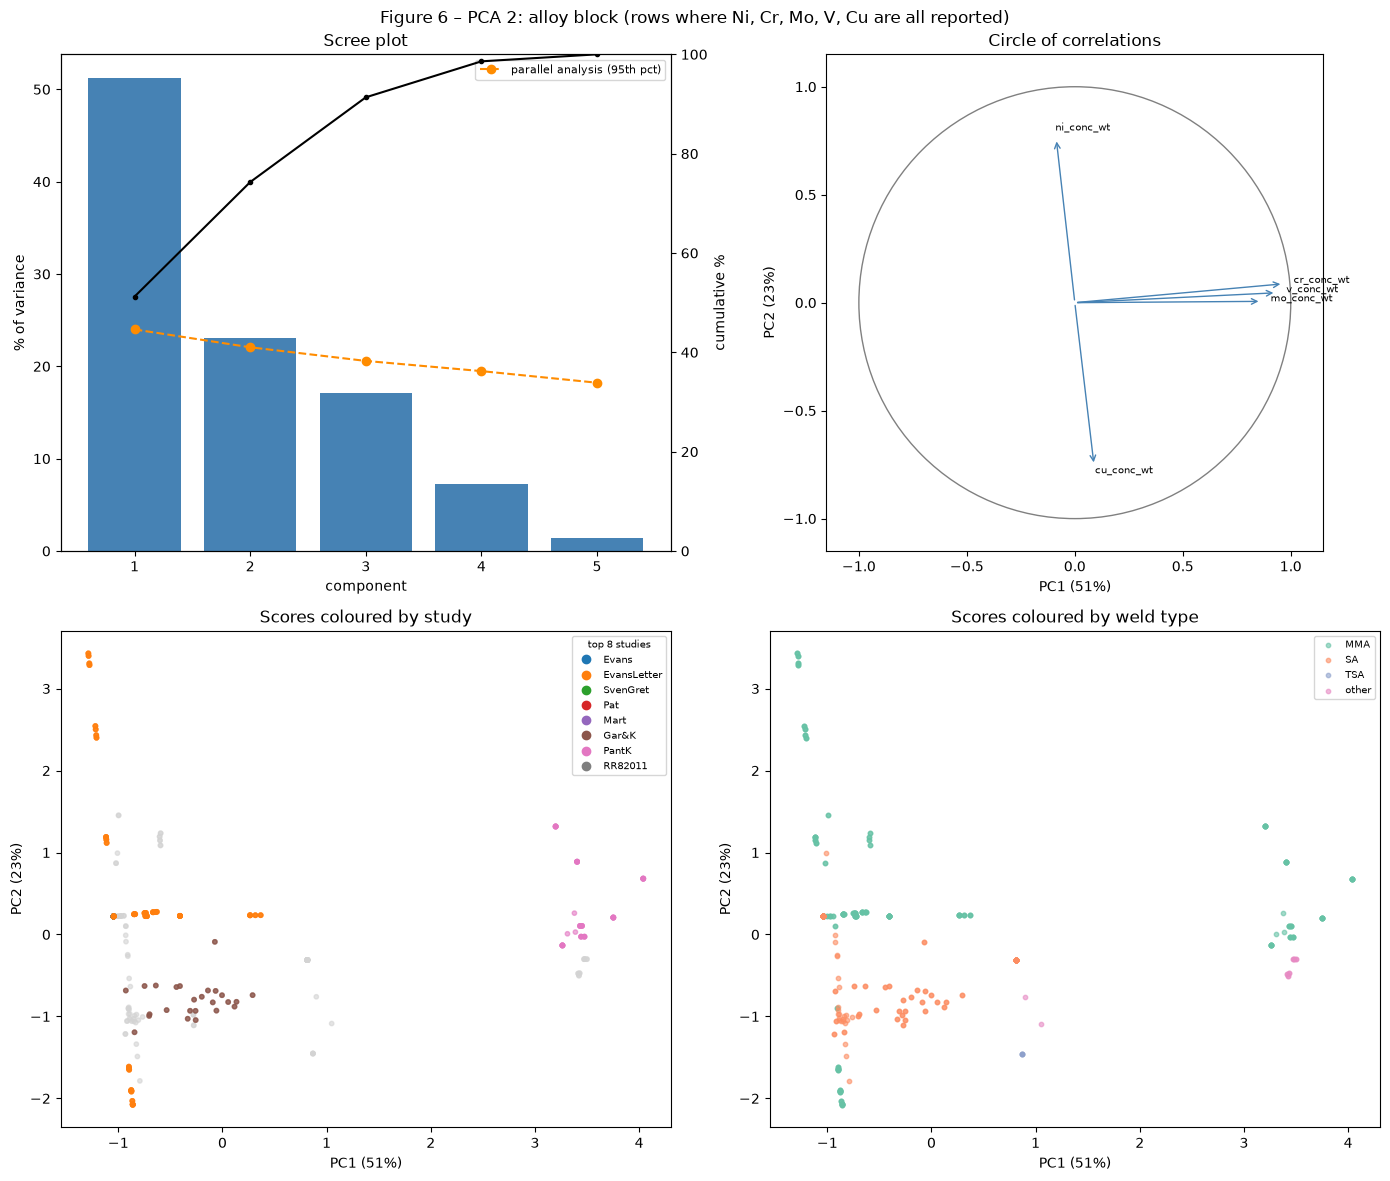

In [9]:
alloy_rows = clean.loc[clean[alloy_block].notna().all(axis=1), alloy_block]
reports["2 alloy"] = pca_report(standardise_for_pca(alloy_rows))
summarise("2 alloy", reports["2 alloy"])
print("rows by study:", source.loc[alloy_rows.index].value_counts().head(6).to_dict())
for pc, values in loadings_table(reports["2 alloy"], k=3, top=5).items():
    print(" ", pc, values)
r2 = reports["2 alloy"]
print("\nshare of PC1 variance that is NOT explained by the study (adjusted):",
      round(1 - eta_squared(r2.scores["PC1"], source.loc[alloy_rows.index]), 2))
pca_figure("Figure 6 \u2013 PCA 2: alloy block (rows where Ni, Cr, Mo, V, Cu are all reported)", r2, "fig06_pca2_alloy.png")

**Your conclusions:**

- **What it rests on**: 418 rows, mostly five studies (EvansLetter 156, PantK 54, Gar&K 50, RR82011 46, Cunh 38). The alloy conclusions below describe these studies.
- **Strongly compressible**: PC1 (51%) is a Cr-V-Mo axis (0.96 / 0.93 / 0.86) and PC2 (23%) opposes Ni (+0.76) to Cu (-0.75); 3 components give 91%, and parallel analysis keeps 2 (74%).
- **But the alloy axis is the study**: the adjusted eta-squared of PC1 against `source` is 0.97, so only 3% of its variance is within a study. As a derived feature it would work almost as a study identifier.

### 2.3 PCA 3: all 25 features, median for the missing values

  PC1 {'cr_conc_wt': 0.83, 'mo_conc_wt': 0.79, 'pwht_temp_c': 0.74, 'n_conc_ppm': 0.72, 'v_conc_wt': 0.7, 'nb_conc_ppm': 0.56}
  PC2 {'current_a': 0.84, 'heat_input_kj_mm': 0.84, 'voltage_v': 0.79, 'p_conc_wt': 0.68, 's_conc_wt': 0.64, 'cu_conc_wt': 0.4}
  PC3 {'as_conc_ppm': 0.7, 'sn_conc_ppm': 0.68, 'nb_conc_ppm': 0.53, 'v_conc_wt': 0.49, 'o_conc_ppm': -0.44, 'c_conc_wt': 0.42}

correlation of each component with the number of imputed values in the row: [-0.19, -0.26, -0.05, -0.08, -0.04, -0.08]

|cosine| between the loadings of PCA 1 and PCA 3 on the 13 shared variables:
          PCA3 PC1  PCA3 PC2  PCA3 PC3
PCA1 PC1      0.45      0.96      0.03
PCA1 PC2      0.82      0.25      0.57
PCA1 PC3      0.28      0.08      0.56


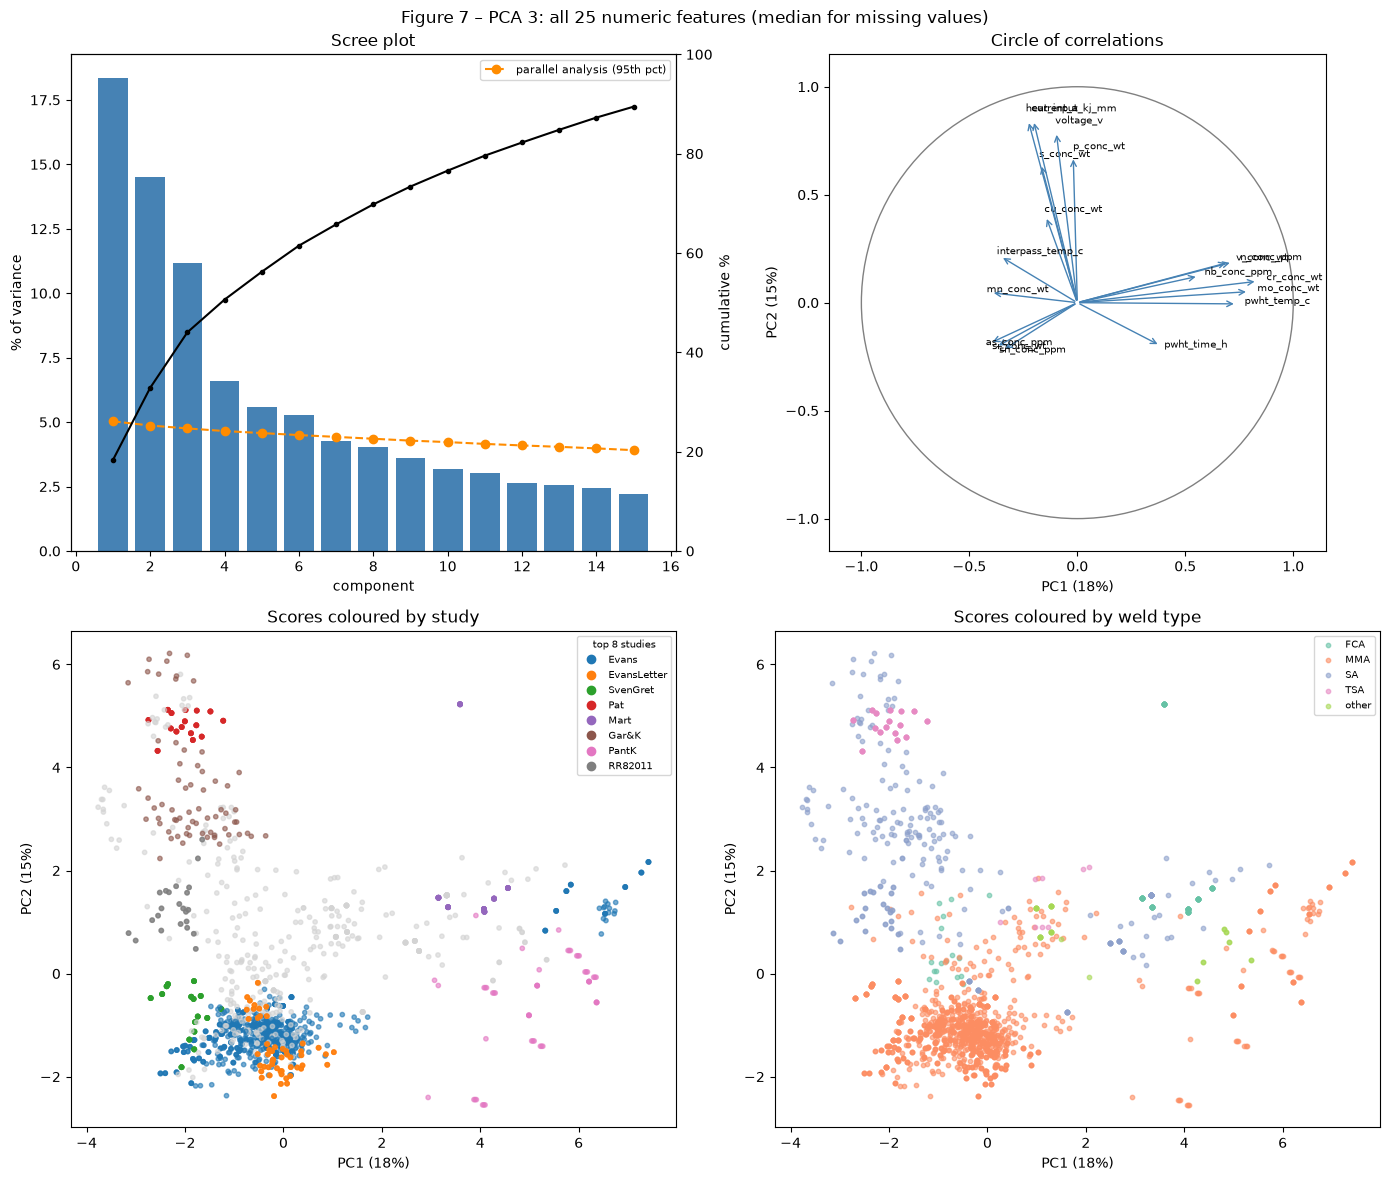

In [10]:
full = clean[NUMERIC_FEATURES]
reports["3 all25"] = pca_report(standardise_for_pca(full, impute_median=True))
summarise("3 all25", reports["3 all25"])
for pc, values in loadings_table(reports["3 all25"], k=3, top=6).items():
    print(" ", pc, values)
n_imputed = full.isna().sum(axis=1)
r3 = reports["3 all25"]
print("\ncorrelation of each component with the number of imputed values in the row:",
      [round(float(np.corrcoef(r3.scores[f"PC{k}"], n_imputed)[0, 1]), 2) for k in range(1, 7)])

shared = [c for c in core if c in r3.correlations.index]
r1 = reports["1 core"]
cos = pd.DataFrame({f"PCA3 PC{j}": [abs(np.dot(r1.correlations.loc[shared, f"PC{i}"], r3.correlations.loc[shared, f"PC{j}"])
                                       / (np.linalg.norm(r1.correlations.loc[shared, f"PC{i}"]) * np.linalg.norm(r3.correlations.loc[shared, f"PC{j}"])))
                                   for i in (1, 2, 3)] for j in (1, 2, 3)}, index=["PCA1 PC1", "PCA1 PC2", "PCA1 PC3"])
print("\n|cosine| between the loadings of PCA 1 and PCA 3 on the 13 shared variables:")
print(cos.round(2).to_string())
pca_figure("Figure 7 \u2013 PCA 3: all 25 numeric features (median for missing values)", r3, "fig07_pca3_all25.png", label_threshold=0.4)

**Your conclusions:**

- **Same structure on all rows**: PC1 (18%) mixes alloy elements with PWHT and nitrogen (Cr 0.83, Mo 0.79, PWHT temperature 0.74, N 0.72, V 0.70, Nb 0.56), consistent with alloyed steels being heat treated; PC2 (14.5%) is the arc-energy axis of PCA 1 (|cosine| 0.96), and PCA 1's PWHT axis reappears as PCA 3's PC1 (0.82).
- **Median filling does not drive the leading components**: their correlation with the number of imputed values in a row is -0.19 (PC1) and -0.26 (PC2), and about 0 afterwards.
- **Not compressible**: 3 components capture 44%; 80 / 90 / 95% need 12 / 16 / 19 components; parallel analysis keeps 6 (61.5%).
- **Highly study-specific**: eta-squared against `source` 0.65 / 0.87 / 0.80 for PC1-3.

### 2.4 PCA 4: with missing / censored flags and one-hot (diagnostic)

64 columns, 39 of them flags or one-hot
share of the squared loadings carried by flags / one-hot, PC1-PC3: [0.91, 0.59, 0.23]
  PC1 {'electrode_polarity_unknown': 0.86, 'nb_conc_ppm_censored': 0.82, 'b_conc_ppm_censored': 0.79, 'al_conc_ppm_censored': 0.78, 'electrode_polarity_+': -0.78, 'current_type_unknown': 0.78}
  PC2 {'mo_conc_wt_missing': 0.88, 'weld_type_MMA': 0.79, 'cr_conc_wt_missing': 0.74, 'ni_conc_wt_missing': 0.65, 'current_a': -0.61, 'heat_input_kj_mm': -0.57}
  PC3 {'mo_conc_wt': 0.72, 'cr_conc_wt': 0.7, 'pwht_temp_c': 0.63, 'current_a': -0.58, 'heat_input_kj_mm': -0.58, 'v_conc_wt': 0.55}


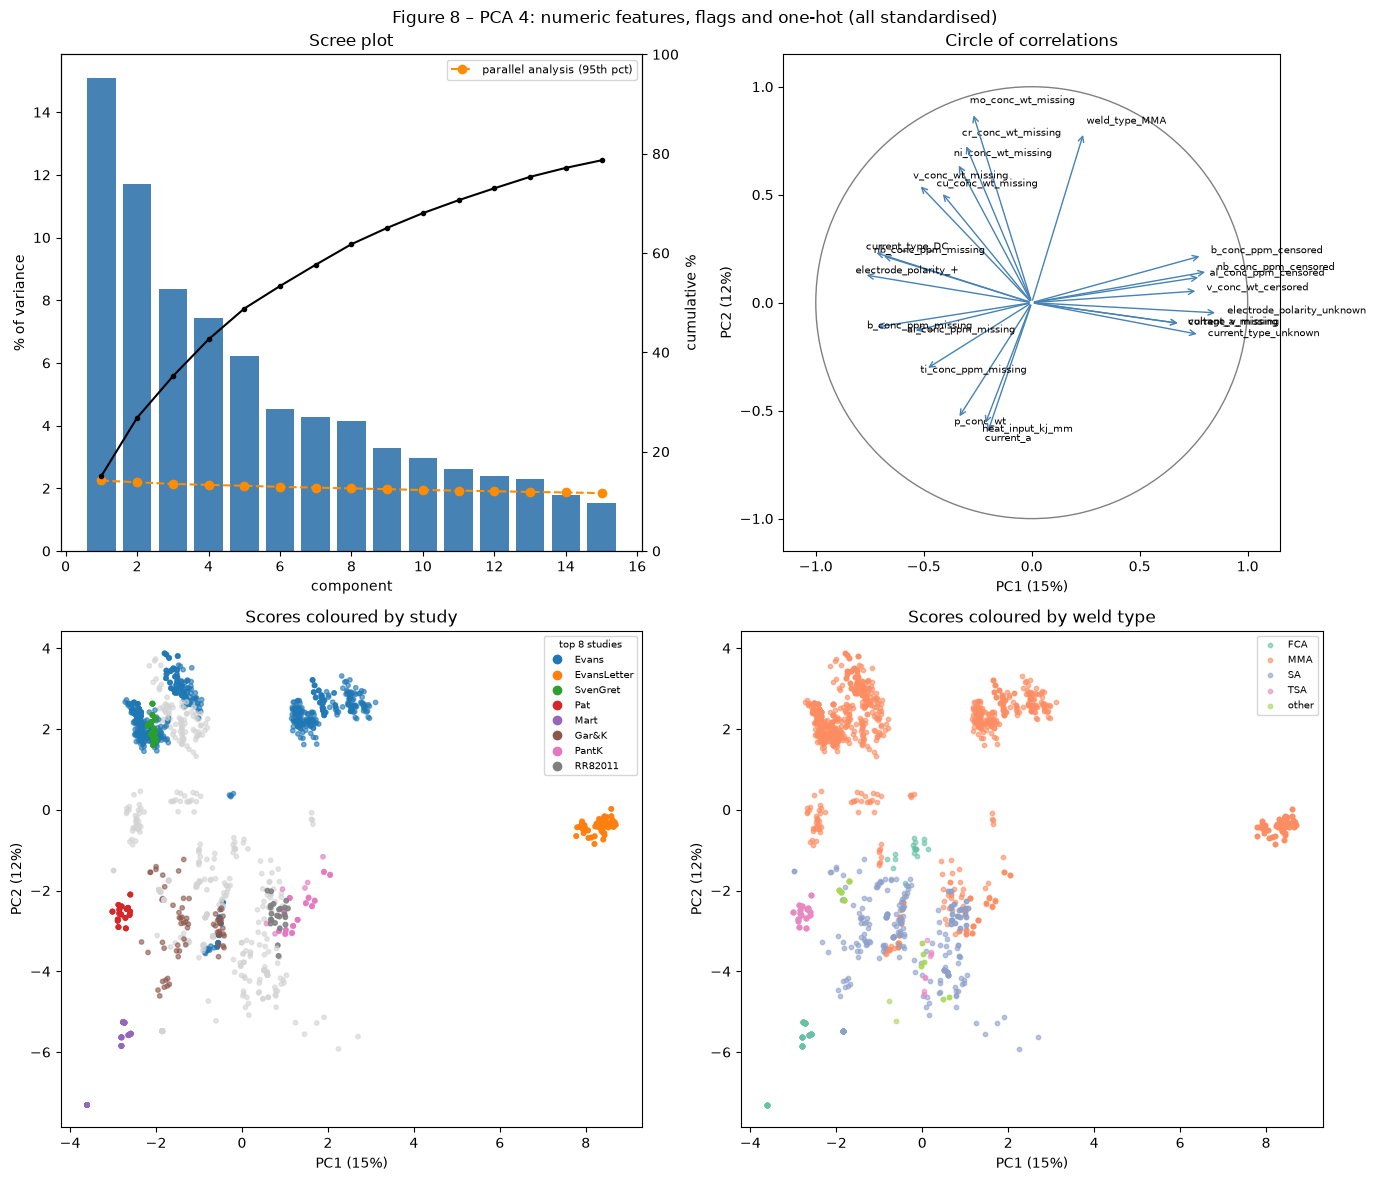

In [11]:
spec = feature_spec(clean, "yield_strength_mpa")
matrix = build_preprocessor("linear", spec).fit_transform(clean[spec.columns])
reports["4 with flags"] = pca_report(standardise_for_pca(matrix, log_columns=[]))
summarise("4 with flags", reports["4 with flags"])
r4 = reports["4 with flags"]
is_flag = r4.correlations.index.str.contains(r"_missing$|_censored$|^weld_type_|^current_type_|^electrode_polarity_")
mass = (r4.correlations ** 2)
print(matrix.shape[1], "columns,", int(is_flag.sum()), "of them flags or one-hot")
print("share of the squared loadings carried by flags / one-hot, PC1-PC3:",
      [round(float(mass.loc[is_flag, f"PC{k}"].sum() / mass[f"PC{k}"].sum()), 2) for k in (1, 2, 3)])
for pc, values in loadings_table(r4, k=3, top=6).items():
    print(" ", pc, values)
pca_figure("Figure 8 \u2013 PCA 4: numeric features, flags and one-hot (all standardised)", r4, "fig08_pca4_with_flags.png", label_threshold=0.55)

**Your conclusions:**

- **The reporting pattern is a study fingerprint**: flags and one-hot columns carry 91% of PC1's squared loadings (unknown electrode polarity 0.86, Nb / B / Al censored 0.82 / 0.79 / 0.78, unknown current type 0.78) and 59% of PC2's (Mo / Cr / Ni missing, MMA weld type). Chemistry only returns in PC3.
- **Study visibility rises with the flags**: eta-squared of PC1 against `source` goes from 0.65 (numeric only, PCA 3) to 0.84; PC2 stays at 0.87 and PC3 goes from 0.80 to 0.84.
- **Less compressible**: 16 / 25 / 33 components for 80 / 90 / 95% of 64 columns; parallel analysis keeps 13 (75%).
- **For modeling**: the flags help a model recognise a study it has already seen (good in random CV) and are useless on a new study. Whether they help or hurt must be tested under both protocols in notebook 03, not assumed.

### 2.5 Comparison and dimension reduction

In [12]:
pca_summary = pd.DataFrame(summary_rows).set_index("pca")
pca_summary.to_csv(OUT / "02_pca_summary.csv")
print(pca_summary.T.to_string())

for name in ("1 core", "3 all25"):
    report = reports[name]
    index = report.scores.index
    k = report.n_keep
    variances = report.scores.iloc[:, :k].var()
    t2 = (report.scores.iloc[:, :k] ** 2 / variances).sum(axis=1)
    outliers = pd.DataFrame({"weld_id": raw.loc[index, "weld_id"], "source": source.loc[index], "T2": t2.round(1)})
    outliers = outliers.sort_values("T2", ascending=False).head(10)
    outliers.to_csv(OUT / f"02_pca_outliers_{name.split()[0]}.csv", index=False)
    print(f"\nPCA {name}: 10 rows farthest from the centre in the {k} retained components (Hotelling T2)")
    print(outliers.to_string(index=False))

pca                      1 core  2 alloy  3 all25  4 with flags
rows                    1010.00   418.00  1652.00       1652.00
variables                 13.00     5.00    25.00         64.00
var_PC1_%                 27.00    51.20    18.40         15.10
var_PC2_%                 20.50    23.10    14.50         11.70
var_PC3_%                 12.20    17.10    11.20          8.30
cum_PC1-3_%               59.70    91.30    44.00         35.20
comps_80%                  7.00     3.00    12.00         16.00
comps_90%                  9.00     3.00    16.00         25.00
comps_95%                 10.00     4.00    19.00         33.00
parallel_keep              3.00     2.00     6.00         13.00
cum_at_parallel_keep_%    59.70    74.30    61.50         75.30
eta2_source_PC1            0.93     0.97     0.65          0.84
eta2_weld_PC1              0.80     0.16     0.17          0.08
eta2_source_PC2            0.60     0.16     0.87          0.87
eta2_weld_PC2              0.37     0.11

**Your conclusions:**

- **Only the alloy block compresses** (5 variables to 3 components for 91%). The 25 numeric inputs do not: 3 components give 44%, 80% needs 12 and 90% needs 16. With about 900 rows per target and 25 variables there is no speed gain to buy, and no reason to expect less overfitting from dropping the last components.
- **In all four PCAs the leading components are study axes** (adjusted eta-squared of PC1 against `source`: 0.93, 0.97, 0.65, 0.84). A PCA used as a preprocessing step would hand a model study identity in a compact form, so it has to be tested under the study-grouped protocol rather than assumed useful.
- **Outliers are isolated rows, not a pattern**: besides the `Mart-G*` replicates, the farthest rows of PCA 3 are `Wats-1981-CWO`, `Kluket-CuMnB-1994-11/12`, `Cunh-1982-19aw/ht` and `PakSven-1990-9`. They should be inspected before any removal; none is removed here.

### 2.6 Is a derived "alloy family" feature worth it?

PCA 2 and the histograms of 4.A suggest three families on chromium (no row has 3-6 wt% Cr). Families are only defined where Cr is
reported: a missing Cr is *not* "no chromium" (it is missing by study), so those rows stay `unknown`. We test whether the family
tells something about the mechanical properties **within a study**, which is the only evidence that is not about who measured.

            rows  studies  top_study_share_%
cr_conc_wt                                  
unknown      868        9                 69
Cr<1         404       14                 30
Cr 1-4       260       13                 27
Cr>4         120        4                 45

Share of each target's variance explained by the Cr family (adjusted eta2):
               target  rows  eta2_family_overall  eta2_family_within_study
   yield_strength_mpa   378                 0.18                      0.04
              uts_mpa   352                 0.25                      0.11
       elongation_pct   339                 0.29                      0.11
reduction_of_area_pct   349                 0.02                      0.08
   charpy_toughness_j   338                 0.05                      0.01


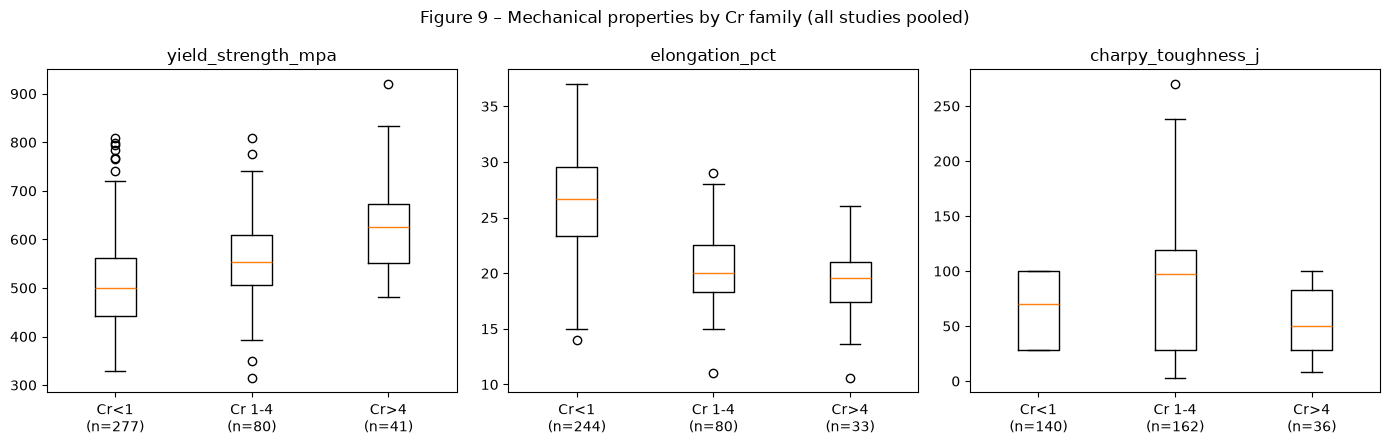

In [13]:
cr = clean["cr_conc_wt"]
family = pd.cut(cr, [-np.inf, 1, 4, np.inf], labels=["Cr<1", "Cr 1-4", "Cr>4"]).astype(object).fillna("unknown")
table = pd.DataFrame({"rows": family.value_counts()})
table["studies"] = [source[family == f].nunique() for f in table.index]
table["top_study_share_%"] = [round(100 * source[family == f].value_counts(normalize=True).iloc[0]) for f in table.index]
print(table.to_string())

known = clean[family != "unknown"]
rows = []
for target in TARGETS:
    d = known[[target]].assign(family=family[known.index], source=source[known.index]).dropna()
    d = d[d.groupby("source")[target].transform("size") >= 5]
    overall = eta_squared(d[target], d["family"])
    d["demeaned"] = d[target] - d.groupby("source")[target].transform("mean")
    rows.append({"target": target, "rows": len(d), "eta2_family_overall": round(overall, 2),
                 "eta2_family_within_study": round(eta_squared(d["demeaned"], d["family"]), 2)})
effect = pd.DataFrame(rows)
effect.to_csv(OUT / "02_alloy_family_effect.csv", index=False)
print("\nShare of each target's variance explained by the Cr family (adjusted eta2):")
print(effect.to_string(index=False))

order = ["Cr<1", "Cr 1-4", "Cr>4"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, target in zip(axes, ["yield_strength_mpa", "elongation_pct", "charpy_toughness_j"]):
    data = [known.loc[family[known.index] == f, target].dropna() for f in order]
    ax.boxplot(data, tick_labels=[f"{f}\n(n={len(x)})" for f, x in zip(order, data)])
    ax.set_title(target)
fig.suptitle("Figure 9 \u2013 Mechanical properties by Cr family (all studies pooled)")
plt.tight_layout()
fig.savefig(FIG / "fig09_cr_family.png", dpi=150)
plt.show()

**Your conclusions:**

- **Families**: Cr < 1 has 404 rows (14 studies), Cr 1-4 has 260 (13) and Cr > 4 has 120 (4 studies, 45% from one); 868 rows are `unknown` because Cr was not reported (9 studies, 69% from `Evans`), which is not the same as no chromium.
- **Most of the family signal is between studies**: the family explains 18% / 25% / 29% of yield strength / UTS / elongation overall, but only 4% / 11% / 11% once the study mean is removed; reduction of area 2% -> 8% and Charpy 5% -> 1%.
- **Decision**: no categorical alloy-family feature. It carries less than the continuous Cr (within-study rho of -0.43 on elongation), and in a study-grouped split it would mostly identify the study. Cr, Mo, V and Nb stay as continuous features.

### 2.7 Replicated rows

A PCA score plot shows rows sitting on top of each other (the ten farthest rows of PCA 1 are all `Mart-G*` with exactly the same T2).
If many rows share the same input vector, a random split puts copies of the same weld on both sides, which a model can simply look up.
A *fingerprint* is the full input vector (25 numeric features + 3 categoricals); for Charpy toughness, two readings of the same weld
at different test temperatures are the same fingerprint, so the temperature is added as a second key.

In [14]:
cols = NUMERIC_FEATURES + ["current_type", "electrode_polarity", "weld_type"]
shared = clean.duplicated(subset=cols, keep=False)
groups = clean[shared].groupby(cols, dropna=False).ngroup()
print(f"rows whose input vector appears at least twice: {shared.sum()} ({shared.mean():.0%}), "
      f"in {groups.nunique()} groups (median size {int(groups.value_counts().median())}, max {groups.value_counts().max()})")
print("rows in such groups, by study:", clean.loc[shared, "source"].value_counts().head(8).to_dict())

rows = []
for label, target, keys in [(t, t, cols) for t in TARGETS if t != "charpy_toughness_j"] + [
        ("charpy_toughness_j (same weld, any temperature)", "charpy_toughness_j", cols),
        ("charpy_toughness_j (same weld and temperature)", "charpy_toughness_j", cols + ["charpy_temp_c"])]:
    d = clean.loc[clean[target].notna(), keys + [target]]
    dup = d.duplicated(subset=keys, keep=False)
    gid = d[dup].groupby(keys, dropna=False).ngroup()
    rows.append({"target": label, "labeled_rows": len(d), "rows_in_replicate_groups": int(dup.sum()),
                 "share_%": round(100 * dup.mean()), "sd_within_group": round(d.loc[dup, target].groupby(gid).std().mean(), 1),
                 "sd_overall": round(d[target].std(), 1)})
replicates = pd.DataFrame(rows)
replicates.to_csv(OUT / "02_replicated_rows.csv", index=False)
print()
print(replicates.to_string(index=False))

rows whose input vector appears at least twice: 875 (53%), in 224 groups (median size 3, max 20)
rows in such groups, by study: {'Evans': 318, 'EvansLetter': 156, 'SvenGret': 96, 'Pat': 79, 'Mart': 70, 'RR82011': 46, 'Chandel&': 23, 'Ditt': 20}

                                         target  labeled_rows  rows_in_replicate_groups  share_%  sd_within_group  sd_overall
                             yield_strength_mpa           780                        80       10              8.3        92.9
                                        uts_mpa           738                        82       11              5.5        88.6
                                 elongation_pct           700                        75       11              1.0         4.9
                          reduction_of_area_pct           705                        75       11              1.0         8.9
charpy_toughness_j (same weld, any temperature)           879                       618       70             49.4        50.

**Your conclusions:**

- **Replicated inputs are common but not equally harmful**: 53% of rows (875, in 224 groups of median size 3, up to 20) share their full input vector with another row, mostly from `Evans` (318), `EvansLetter` (156), `SvenGret` (96), `Pat` (79) and `Mart` (70).
- **Tensile targets**: only 10-11% of the labeled rows have a labeled twin, and twins agree closely (within-group standard deviation 8 vs 93 MPa for yield strength, 5.5 vs 89 for UTS, 1.0 vs 4.9 for elongation, 1.0 vs 8.9 for reduction of area). A random split leaks through these twins, but only for about one row in ten.
- **Charpy toughness is different**: 70% of the labeled rows are the same weld measured at several test temperatures (within-group standard deviation 49 vs 50 overall, because temperature drives the value); only 4% are the same weld at the same temperature. In a random split the other temperatures of a weld sit in the training set, and the model interpolates that weld's own transition curve. Its random-protocol score is the most flattering.
- **Consequence for the protocols**: the gap between the random and the study-grouped scores mixes two things, "new weld" and "new study". Grouping by input fingerprint (same weld, any temperature) as a third protocol would separate them.

### 2.8 What carries information beyond the study? Variance partition and the structure of the targets

Two questions the PCAs raise without answering.

1. **For each input, how much of its variance is the study?** The adjusted eta-squared of a variable against `source` is the share of its variance that only identifies the study. An input with a share close to 1 can tell a model *which study* a row comes from, and little else.
2. **How many dimensions do the targets span, and does the strength / ductility trade-off hold inside a study?** A PCA of the targets, with and without the study mean removed.

                  study_share  rows  studies  median_within_over_overall  within_study_share
current_a                0.98  1404       24                        0.82                0.02
voltage_v                0.95  1404       24                        0.60                0.05
heat_input_kj_mm         0.89  1652       28                        0.47                0.11
mo_conc_wt               0.86   793       21                        0.29                0.14
interpass_temp_c         0.84  1652       28                        1.43                0.16
cr_conc_wt               0.73   784       21                        0.75                0.27
as_conc_ppm              0.73   234        6                        1.57                0.27
v_conc_wt                0.68   928       17                        0.90                0.32
pwht_time_h              0.55  1639       28                        0.57                0.45
sb_conc_ppm              0.51   260        6                        0.

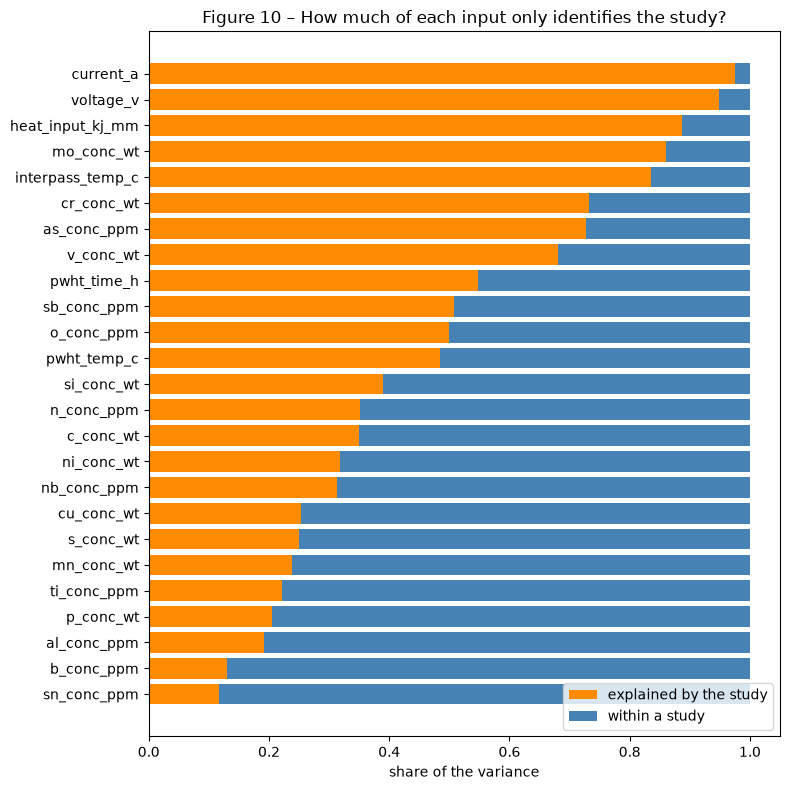

In [15]:
partition = pd.DataFrame({
    "study_share": pd.Series({v: eta_squared(clean[v], source) for v in NUMERIC_FEATURES}),
    "rows": clean[NUMERIC_FEATURES].notna().sum(),
    "studies": pd.Series({v: int((source[clean[v].notna()].value_counts() >= 5).sum()) for v in NUMERIC_FEATURES}),
    "median_within_over_overall": nw.groupby("input")["ratio"].median(),
}).sort_values("study_share", ascending=False)
partition["within_study_share"] = 1 - partition["study_share"]
partition.round(2).to_csv(OUT / "02_variance_partition.csv")
print(partition.round(2).to_string())

rho = partition[["study_share", "median_within_over_overall"]].dropna().corr(method="spearman").iloc[0, 1]
print(f"\nSpearman correlation between an input's study share and the share of its correlations "
      f"with the targets that survives within a study: {rho:.2f}")

fig, ax = plt.subplots(figsize=(8, 8))
shares = partition["study_share"].clip(0, 1)
ax.barh(partition.index, shares, color="darkorange", label="explained by the study")
ax.barh(partition.index, 1 - shares, left=shares, color="steelblue", label="within a study")
ax.invert_yaxis()
ax.set_xlabel("share of the variance")
ax.set_title("Figure 10 \u2013 How much of each input only identifies the study?")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIG / "fig10_variance_partition.png", dpi=150)
plt.show()

**Your conclusions (variance partition):**

- **Inputs that are mostly the study**: current 98%, voltage 95%, heat input 89%, Mo 86%, interpass temperature 84%, Cr 73%, As 73%, V 68%. For the three arc variables only 2-11% of the variance lies within a study, so they say which study a row comes from and almost nothing else.
- **Inputs that vary mostly within a study**: Sn 88%, B 87%, Al 81%, P 79%, Ti 78%, Mn 76%, S 75%, Cu 75%, Nb 69%, Ni 68%.
- **The study share does not predict which inputs lose their correlations within a study.** The Spearman correlation between an input's study share and the share of its target correlations that survives within a study is -0.09. Interpass temperature (84% study) keeps its correlations (median ratio 1.43) while Cu (25% study) and Ni (32%) lose nearly all (0.05 and 0.17). A correlation with a target is between-study when the *covariance* is, whatever share of the input's own variance is the study. The partition describes the inputs; it is not a screening rule, and the within-source coefficient of 4.E remains the criterion. (I had suggested it as a direct guide for choosing variables: this check does not support that.)
- **Caveat**: the median ratio is computed over at most five targets and is unstable when the overall coefficient is small (As 1.57 on 6 studies, Si 1.87).


                          pca  rows  PC1_%  PC2_%  PC3_%  parallel_keep
          4 tensile, all rows   650   75.7   14.7    8.3              1
4 tensile, study mean removed   638   77.1   14.7    6.9              1
        5 targets with Charpy   134   65.1   23.4    8.9              1

                      4 tensile, all rows       4 tensile, study mean removed       5 targets with Charpy      
                                      PC1   PC2                           PC1   PC2                   PC1   PC2
yield_strength_mpa                   0.90  0.37                          0.90  0.38                  0.77  0.55
uts_mpa                              0.96  0.08                          0.95  0.21                  0.97  0.04
elongation_pct                      -0.86 -0.09                         -0.89  0.09                 -0.67 -0.54
reduction_of_area_pct               -0.75  0.66                         -0.76  0.62                 -0.87  0.43
charpy_toughness_j                    N

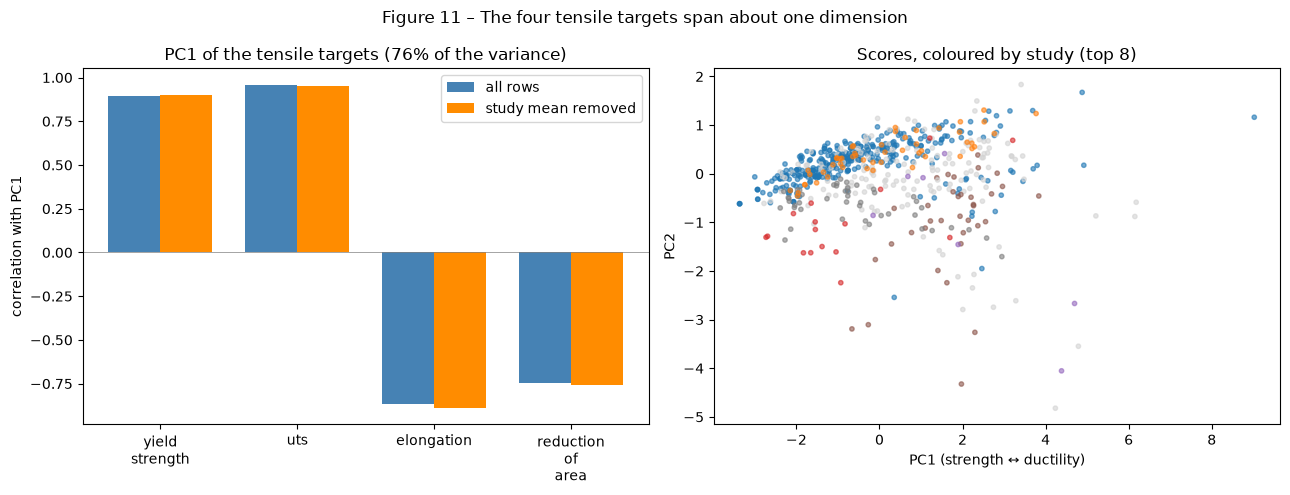

In [16]:
tensile = [t for t in TARGETS if t != "charpy_toughness_j"]


def target_pca(columns, within=False):
    data = clean[columns].dropna()
    if within:
        s = source.loc[data.index]
        data = (data - data.groupby(s).transform("mean"))[s.map(s.value_counts()) >= 5]
    return pca_report((data - data.mean()) / data.std()), len(data)


runs = {"4 tensile, all rows": target_pca(tensile),
        "4 tensile, study mean removed": target_pca(tensile, within=True),
        "5 targets with Charpy": target_pca(TARGETS)}
variance = pd.DataFrame([{"pca": name, "rows": n,
                          **{f"PC{i}_%": round(100 * rep.explained_ratio.iloc[i - 1], 1) for i in (1, 2, 3)},
                          "parallel_keep": rep.n_keep} for name, (rep, n) in runs.items()])
loadings = pd.concat({name: rep.correlations[["PC1", "PC2"]].round(2) for name, (rep, _) in runs.items()}, axis=1)
variance.to_csv(OUT / "02_target_pca_variance.csv", index=False)
loadings.to_csv(OUT / "02_target_pca_loadings.csv")
print(variance.to_string(index=False))
print()
print(loadings.to_string())
print("\nrows with all four tensile targets:", int(clean[tensile].notna().all(axis=1).sum()),
      "| rows with all five targets:", int(clean[TARGETS].notna().all(axis=1).sum()))
rep_all = runs["4 tensile, all rows"][0]
print("share of the strength axis (PC1 score) explained by the study:",
      round(eta_squared(rep_all.scores["PC1"], source.loc[rep_all.scores.index]), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
width = 0.38
x = np.arange(len(tensile))
axes[0].bar(x - width / 2, runs["4 tensile, all rows"][0].correlations["PC1"], width, label="all rows", color="steelblue")
axes[0].bar(x + width / 2, runs["4 tensile, study mean removed"][0].correlations["PC1"], width, label="study mean removed", color="darkorange")
axes[0].set_xticks(x, [t.replace("_pct", "").replace("_mpa", "").replace("_", "\n") for t in tensile])
axes[0].axhline(0, color="gray", linewidth=0.5)
axes[0].set_ylabel("correlation with PC1")
axes[0].set_title(f"PC1 of the tensile targets ({runs['4 tensile, all rows'][0].explained_ratio.iloc[0]:.0%} of the variance)")
axes[0].legend()
scores = rep_all.scores
axes[1].scatter(scores["PC1"], scores["PC2"], s=10, alpha=0.6, c=source.loc[scores.index].map(palette).fillna("lightgray"))
axes[1].set_xlabel("PC1 (strength \u2194 ductility)")
axes[1].set_ylabel("PC2")
axes[1].set_title("Scores, coloured by study (top 8)")
fig.suptitle("Figure 11 \u2013 The four tensile targets span about one dimension")
plt.tight_layout()
fig.savefig(FIG / "fig11_target_pca.png", dpi=150)
plt.show()

**Your conclusions (structure of the targets):**

- **The four tensile targets are about one-dimensional**: PC1 carries 75.7% of the variance on the 650 complete rows (yield strength 0.90, UTS 0.96 against elongation -0.86 and reduction of area -0.75) and parallel analysis keeps one component. PC2 (14.7%) is mostly reduction of area against yield strength (0.66 / 0.37).
- **The trade-off holds inside studies**: with the study mean removed, PC1 is 77.1% with the same loadings (0.90 / 0.95 / -0.89 / -0.76). It is a property of the weld metal, not an artefact of pooling studies.
- **Most of the variation to explain is within studies**: only 28% of the variance of the strength axis (PC1 score) is between studies, whereas the arc variables are 89-98% study. The targets vary within studies where the process variables barely do, which is consistent with 4.E.
- **Charpy toughness is related, not independent**: on the 134 rows with all five targets it loads -0.72 on PC1 (with ductility) and 0.62 on PC2. It rests on few complete rows and depends on the test temperature.
- **Correction**: 650 rows have all four tensile targets, not 134; the figure of 134 comes from Charpy. A joint model of the four tensile properties is feasible (multi-output, or one strength score plus residuals); Charpy toughness is modeled apart.


## 3. Decisions for notebook 03

1. **Keep the cleaning rules**: `x/2` plus the `_censored` flag. The fill value is immaterial (1.5); dropping the censored rows is the biased choice.
2. **Linear family**: consider adding Al, Nb and V to the shifted-log list (skew 1.7-2.1 once cleaned); decide with an ablation in 03.
3. **No derived alloy-family feature and no PCA scores by default.** Test, under both protocols, three variants in 03: with and without the missing / censored flags, and with and without PCA scores fitted inside each training fold. The leading components and the flags are study fingerprints.
4. **Select features on the within-study coefficient** (4.E, re-confirmed on cleaned data): Cr, V, Nb and Mn are credible drivers; voltage, heat input and current are mostly study identifiers.
5. **Add a third protocol grouped by input fingerprint** (same weld, any temperature) to separate "new weld" from "new study", and report the Charpy random score with that caveat. This changes the evaluation design validated earlier, so it needs the user's agreement before it goes into `src.evaluation`.
6. **Do not remove the isolated PCA outliers** before inspecting them (2.5).
7. **Targets**: test a joint model of the four tensile properties on their 650 complete rows (multi-output, or a strength score plus residuals) against four separate models; keep Charpy toughness apart, with its test temperature.
8. **Variance partition (2.8) is descriptive, not a screening rule**: feature screening stays on the within-study coefficient of 4.E.
